# 03. Results

Run `newsgate all --config configs/synthetic.yaml` first (add `--final` for the holdout).

In [1]:
import pandas as pd
from IPython.display import Image, display
from newsgate.config import load_config
from newsgate.pipeline import RunPaths

cfg = load_config('configs/synthetic.yaml')
root = RunPaths.from_config(cfg).root
root

PosixPath('outputs/synthetic_demo')

## Does news improve the forecast? (negative Brier difference = news helps)

In [2]:
pd.read_csv(root / 'comparisons.csv')[['comparison', 'mean_diff', 'ci_low', 'ci_high', 'p_value', 'p_holm']].round(5)

,comparison,mean_diff,ci_low,ci_high,p_value,p_holm
0,logistic: + attention vs price-only,-0.00015,-0.00028,0.00001,0.064,0.576
1,logistic: + sentiment vs price-only,-0.00010,-0.00022,0.00001,0.076,0.608
2,logistic: + all news vs price-only,-0.00010,-0.00024,0.00006,0.246,1.000
3,logistic: all news vs + attention,0.00005,-0.00004,0.00014,0.348,1.000
4,lightgbm: + attention vs price-only,-0.00014,-0.00027,0.00000,0.052,0.520
5,lightgbm: + sentiment vs price-only,-0.00008,-0.00019,0.00004,0.196,1.000
6,lightgbm: + all news vs price-only,-0.00010,-0.00025,0.00004,0.190,1.000
7,lightgbm: all news vs + attention,0.00003,-0.00007,0.00014,0.618,1.000
8,gate vs price-only,-0.00006,-0.00022,0.00010,0.452,1.000
9,gate vs news model,0.00003,-0.00004,0.00010,0.328,1.000


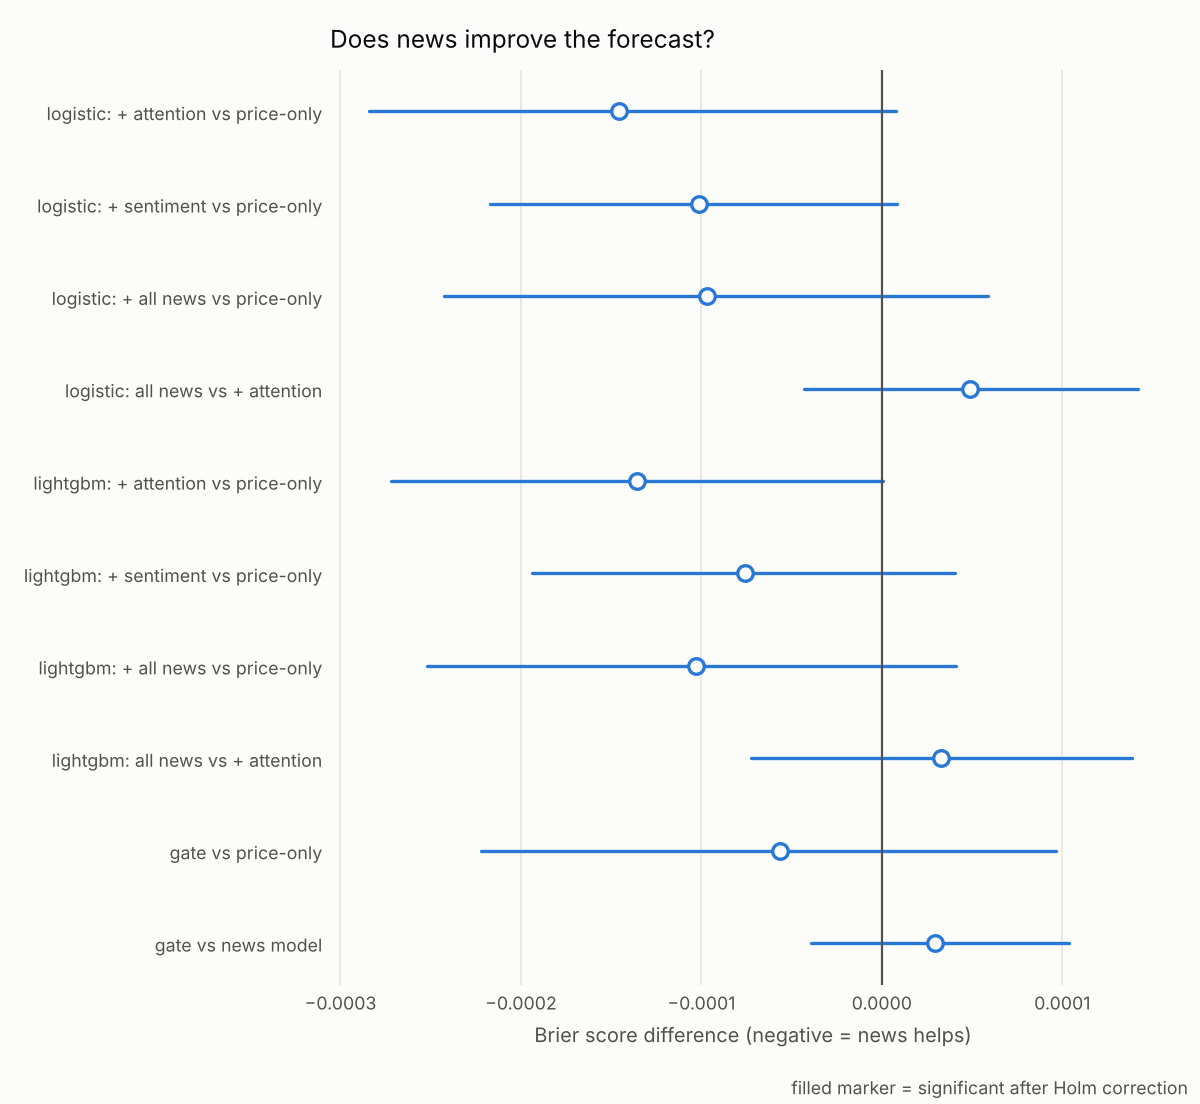

In [3]:
display(Image(root / 'figures' / 'fig1_brier_differences.png'))

## Accuracy of each model

In [4]:
pd.read_csv(root / 'model_metrics.csv').round(4)

,model,n_rows,brier,brier_skill_vs_rate,auroc,ece
0,lightgbm:price_attention,13488,0.1024,0.0309,0.6399,0.0128
1,lightgbm:price_news,13488,0.1024,0.0306,0.6394,0.0102
2,lightgbm:price_sentiment,13488,0.1024,0.0304,0.6398,0.0104
3,logistic:price_attention,13488,0.1025,0.0299,0.6397,0.0123
4,lightgbm:price_only,13488,0.1025,0.0296,0.6376,0.0102
5,logistic:price_sentiment,13488,0.1025,0.0295,0.6407,0.0118
6,logistic:price_news,13488,0.1025,0.0295,0.6389,0.0110
7,logistic:price_only,13488,0.1026,0.0286,0.6375,0.0112
8,historical_rate,13488,0.1057,0.0000,0.4907,0.0209
9,gate,10464,0.1057,0.0363,0.6497,0.0111


## Calibration

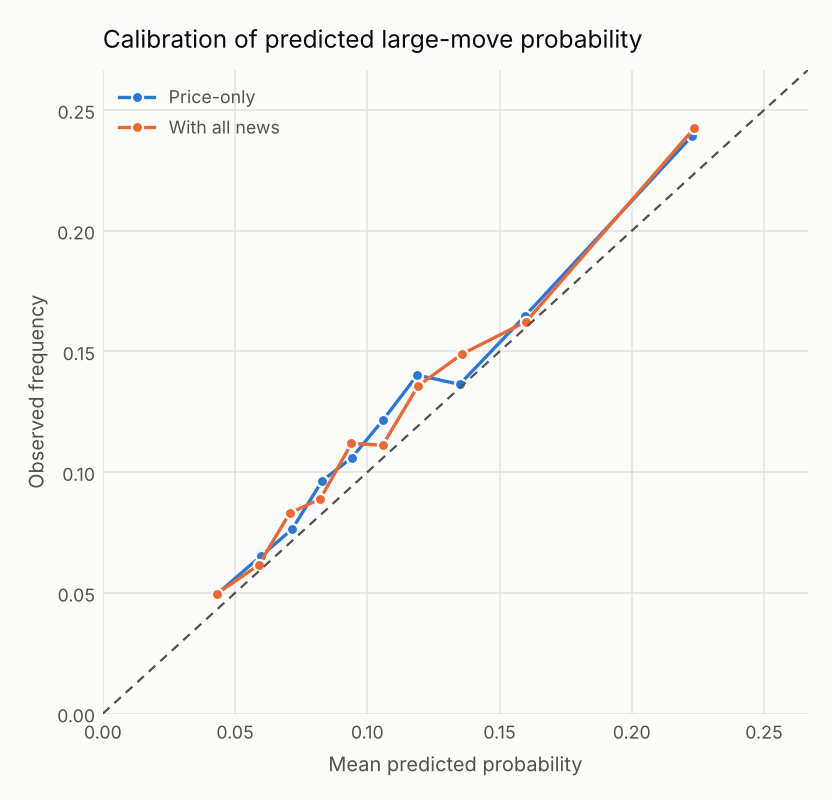

In [5]:
display(Image(root / 'figures' / 'fig2_calibration.png'))

## The gate against simple abstention rules

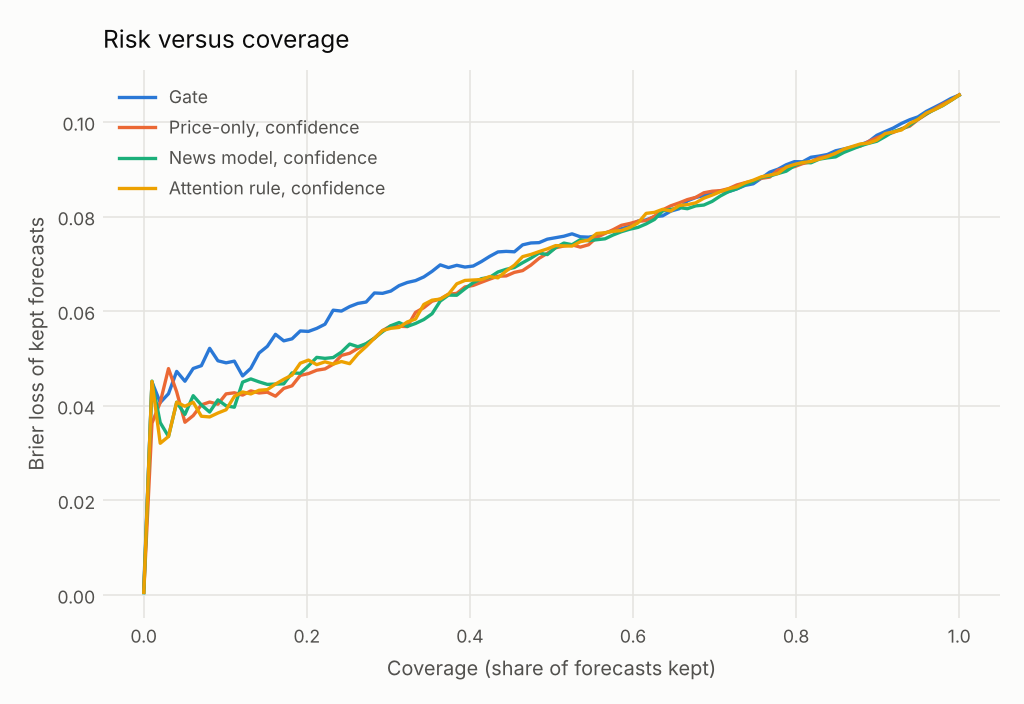

In [6]:
display(Image(root / 'figures' / 'fig3_risk_coverage.png'))

## Does the benefit survive across sectors, coverage levels, market regimes and years? (H3)

In [7]:
pd.read_csv(root / 'robustness.csv').round(5)

,group,level,n_rows,mean,ci_low,ci_high,p_value,n_dates
0,sector,Energy,2248,0.00011,-0.00027,0.00046,0.662,562
1,sector,Financials,562,-0.00012,-0.00073,0.00047,0.752,562
2,sector,Health Care,4496,-0.00014,-0.00033,0.00012,0.344,562
3,sector,Industrials,2248,-0.00018,-0.00055,0.00012,0.214,562
4,sector,Technology,3934,-0.00014,-0.00043,0.00016,0.380,562
5,coverage_group,low coverage,4496,-0.00002,-0.00028,0.00029,0.972,562
6,coverage_group,mid coverage,4496,-0.00013,-0.00035,0.00010,0.298,562
7,coverage_group,high coverage,4496,-0.00016,-0.00041,0.00003,0.102,562
8,regime,calm market,4496,0.00003,-0.00013,0.00019,0.824,188
9,regime,normal market,4496,0.00002,-0.00015,0.00035,0.478,188


## Sentiment deciles and the event timeline

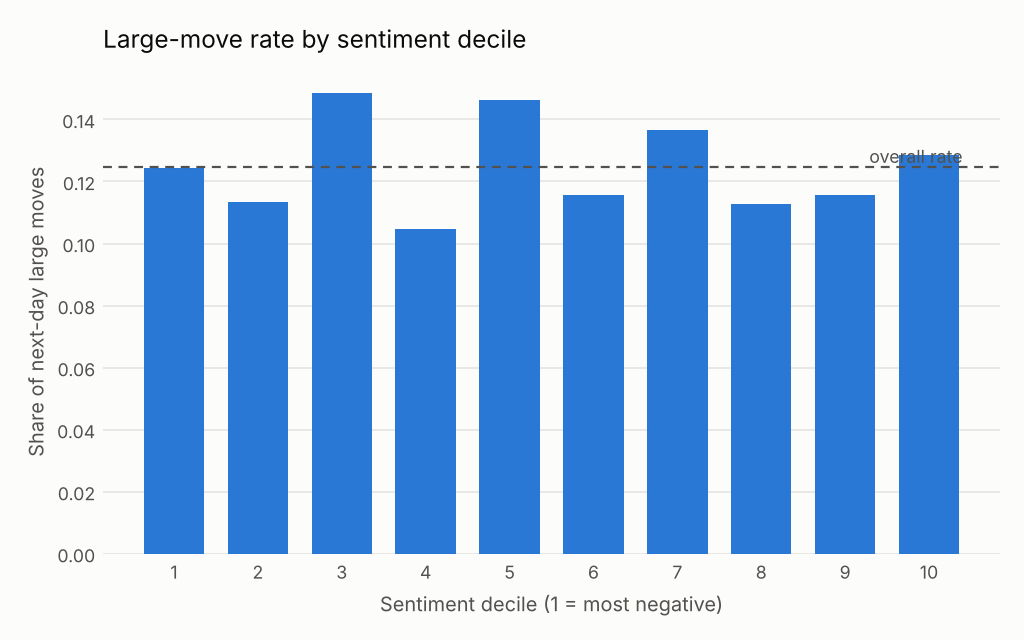

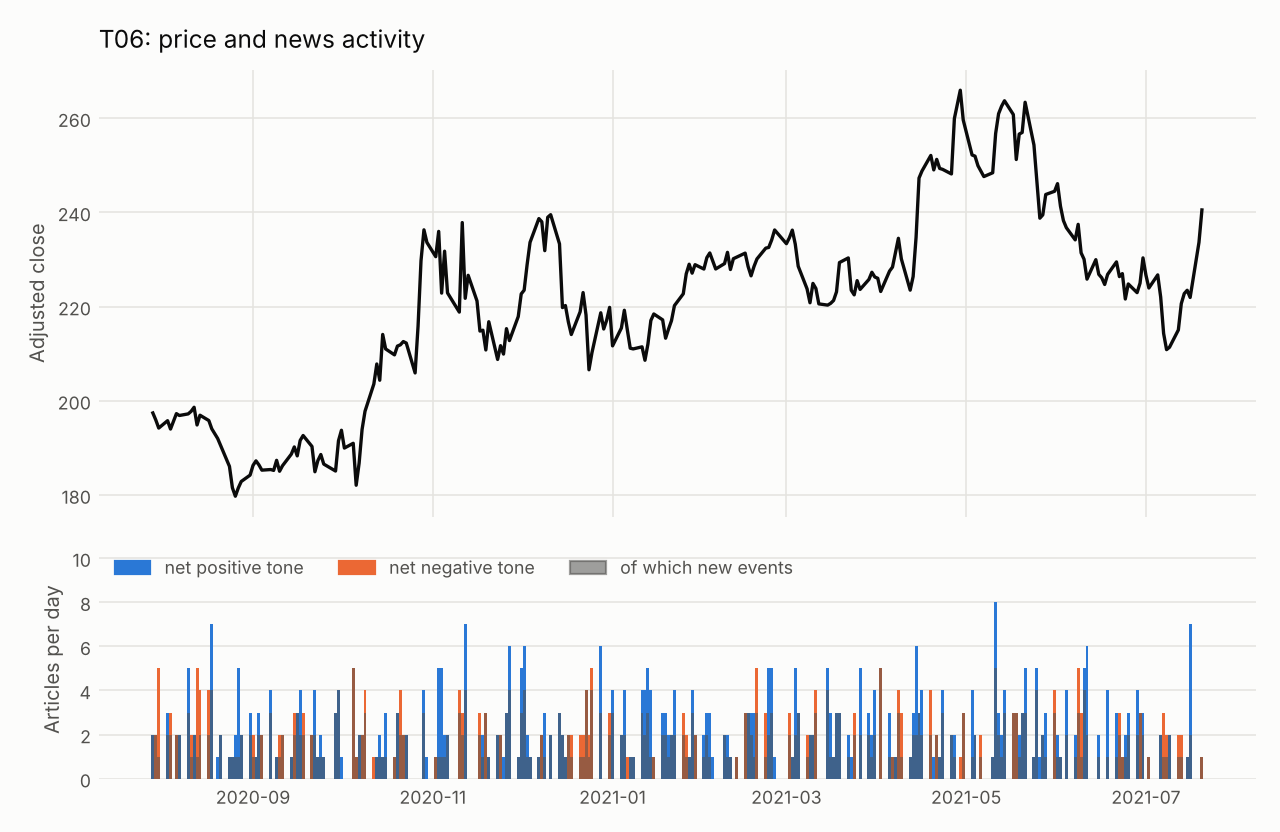

In [8]:
display(Image(root / 'figures' / 'fig4_sentiment_deciles.png'))
display(Image(root / 'figures' / 'fig5_event_timeline.png'))

## Final holdout (only after the design is frozen)

In [9]:
path = root / 'comparisons_holdout.csv'
pd.read_csv(path).round(5) if path.exists() else 'Run `newsgate holdout` once the design is frozen.'

,comparison,challenger,baseline,n_rows,baseline_brier,mean_diff,relative_change_pct,ci_low,ci_high,n_dates,p_value,p_holm,challenger_better
0,logistic: + attention vs price-only,p__logistic__price_attention,p__logistic__price_only,6432,0.10174,-0.00024,-0.23500,-0.00054,0.00003,268,0.088,0.792,False
1,logistic: + sentiment vs price-only,p__logistic__price_sentiment,p__logistic__price_only,6432,0.10174,0.00001,0.00910,-0.00023,0.00020,268,0.998,1.000,False
2,logistic: + all news vs price-only,p__logistic__price_news,p__logistic__price_only,6432,0.10174,-0.00014,-0.13924,-0.00044,0.00014,268,0.314,1.000,False
3,logistic: all news vs + attention,p__logistic__price_news,p__logistic__price_attention,6432,0.10150,0.00010,0.09598,0.00002,0.00017,268,0.022,0.220,False
4,lightgbm: + attention vs price-only,p__lightgbm__price_attention,p__lightgbm__price_only,6432,0.10151,-0.00028,-0.27288,-0.00062,0.00014,268,0.184,1.000,False
5,lightgbm: + sentiment vs price-only,p__lightgbm__price_sentiment,p__lightgbm__price_only,6432,0.10151,-0.00019,-0.18261,-0.00052,0.00013,268,0.252,1.000,False
6,lightgbm: + all news vs price-only,p__lightgbm__price_news,p__lightgbm__price_only,6432,0.10151,-0.00017,-0.16756,-0.00053,0.00033,268,0.508,1.000,False
7,lightgbm: all news vs + attention,p__lightgbm__price_news,p__lightgbm__price_attention,6432,0.10124,0.00011,0.10562,-0.00003,0.00027,268,0.104,0.832,False
8,gate vs price-only,p__gate,p__lightgbm__price_only,6432,0.10151,-0.00023,-0.22433,-0.00054,0.00019,268,0.232,1.000,False
9,gate vs news model,p__gate,p__lightgbm__price_news,6432,0.10134,-0.00006,-0.05687,-0.00020,0.00006,268,0.338,1.000,False
